# Estudio contextual controlado: nueve variantes

Panel definitivo: **33 β × 51 particiones × 3 semillas**, K80, tres redes y AA/AP/AO/PA/PP/PO/OA/OP/OO.
A = media; P = pseudosentido congelado; O = ocurrencia. Primera letra: memoria; segunda: consulta.

Este notebook reutiliza resultados autenticados. No ejecuta BERT, clasificadores ni ajustes estadísticos. El código científico original se conserva en FuenteCientifica, fuera de esta ruta de ejecución. Las 100 posiciones por palabra no constituyen réplicas independientes.

In [1]:
from pathlib import Path
import sys, importlib
from IPython.display import display
HERE = Path.cwd().resolve()
BASE = next((p for p in (HERE, HERE / "EstudioContextual/ExperimentoContextual", HERE / "ExperimentoContextual")
             if (p / "CodigoComun/contextual_guardado.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Abre el notebook desde ProyectoTesis o ExperimentoContextual.")
sys.path.insert(0, str(BASE / "CodigoComun"))
import contextual_guardado as figs
RESULTS = figs.SavedStudy(BASE / "ResultadosGuardados/P20_controlado.zip")
VERIFICACION = RESULTS.verify()
display(VERIFICACION)

{'status': 'VERIFIED',
 'run_id': 'bf02d71452872d063717c4b8770a4708b8f1ca85e6eed7616c9fc7a712f09dd8',
 'authenticated_files': 5039,
 'refits': 486,
 'numerical_surfaces': 1215,
 'empirical_cases_reproduced': 243,
 'empirical_max_abs_delta': 1.5265566588595902e-16,
 'experiment_executed': False,
 'models_refitted': False}

## 1. Protocolo, conjuntos y calibración

K80 procede del diseño controlado congelado; aquí no se selecciona K de nuevo. FULL: 414 palabras; COMMON: 376. Las omisiones conservan la geometría. La calibración TRAIN-A es común a las nueve variantes y utiliza los 98 β originales; el análisis usa los 33 β seleccionados.

In [2]:
display(RESULTS.protocol)
FULL = RESULTS.parquet("inputs/full.parquet")
COMMON = RESULTS.parquet("inputs/common.parquet")
print("FULL:", len(FULL), "| COMMON:", len(COMMON))
display(COMMON.groupby(["true_class", "similarity_bin"]).size().unstack())
print("Calibration artifacts:", sum(p.startswith("source_bank/cal/") for p in RESULTS.data))

{'version': 'P20_33x51x3_V1',
 'source_bank_id': '68682213c8913476a11a1ef997136dbcb80ec50eeedb4f466cb8dd8deae8b981',
 'source_contract_sha': '68682213c8913476a11a1ef997136dbcb80ec50eeedb4f466cb8dd8deae8b981',
 'original_beta_indices': [0,
  3,
  6,
  9,
  12,
  15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  52,
  55,
  58,
  61,
  64,
  67,
  70,
  73,
  76,
  79,
  82,
  85,
  88,
  91,
  94,
  97],
 'betas': [0.01,
  0.025,
  0.04,
  0.055,
  0.06999999999999999,
  0.08499999999999999,
  0.09999999999999999,
  0.11499999999999999,
  0.13,
  0.14500000000000002,
  0.16,
  0.17500000000000002,
  0.19,
  0.20500000000000002,
  0.22,
  0.23500000000000001,
  0.25,
  0.27,
  0.28500000000000003,
  0.3,
  0.315,
  0.33,
  0.34500000000000003,
  0.36000000000000004,
  0.375,
  0.39,
  0.405,
  0.42000000000000004,
  0.435,
  0.45,
  0.465,
  0.48000000000000004,
  0.495],
 'splits': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,

FULL: 414 | COMMON: 376


similarity_bin,0,1,2,3,4
true_class,,,,,
0,10,7,13,26,7
1,6,9,7,10,4
2,11,17,5,8,11
3,2,12,9,11,4
4,6,21,10,18,7
5,4,9,15,8,3
6,5,10,10,5,9
7,7,11,13,14,2


Calibration artifacts: 204


## 2. Superficies y modelos guardados

Principal: S_TENSOR_SHARED, ridge 10⁻⁴. Alternativo: H_BETA_LINEAR_Z, ridge 0.1.
Se conservan parámetros, preprocesamiento, diagnósticos, MATCHED5, GRID30 y métricas OOF. MATCHED5 evalúa fidelidad en las palabras observadas; GRID30 evalúa el modelo en 30 posiciones de similitud, con los mismos 33 β.
Las tablas siguientes son los resultados originales para inspección; no se crea una tabla de manuscrito.

In [3]:
display(RESULTS.tables["counts_summary"])
display(RESULTS.tables["statistical_FULL_LOCO"].query("case == 'FULL'"))
display(RESULTS.tables["OOF_metrics"])

,arm,network,words,rows,occurrence_opportunities,word_exposures,mean_word_error
0,AA,mhncs_softmax,414,13662,106533900,1065339,0.032416
1,AA,hfy_entmax_a15,414,13662,106533900,1065339,0.025855
2,AA,hfy_normmax_g2,414,13662,106533900,1065339,0.027717
3,AP,mhncs_softmax,414,13662,106533900,1065339,0.053952
4,AP,hfy_entmax_a15,414,13662,106533900,1065339,0.046894
5,AP,hfy_normmax_g2,414,13662,106533900,1065339,0.048925
6,AO,mhncs_softmax,414,13662,106533900,1065339,0.084327
7,AO,hfy_entmax_a15,414,13662,106533900,1065339,0.077521
8,AO,hfy_normmax_g2,414,13662,106533900,1065339,0.079748
9,PA,mhncs_softmax,414,13662,106533900,1065339,0.030885


,model,candidate,arm,network,case,omitted_label,n_classes,n_units,family,alpha,...,grid_delta_T3,RMSE_refit_vs_aggregation_only,aggregation_only_T1,aggregation_only_T2,aggregation_only_T3,aggregation_only_ALL3_expected,aggregation_only_T1T2,relative_change_T1,relative_change_T2,relative_change_T3
0,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AA,mhncs_softmax,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,6.863790e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AA,hfy_entmax_a15,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,-9.250202e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AA,hfy_normmax_g2,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,-7.593565e-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,AA,mhncs_softmax,FULL,NaN,8,414,H_BETA_LINEAR_Z,0.1000,...,-3.058645e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,AA,hfy_entmax_a15,FULL,NaN,8,414,H_BETA_LINEAR_Z,0.1000,...,-4.181133e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,AA,hfy_normmax_g2,FULL,NaN,8,414,H_BETA_LINEAR_Z,0.1000,...,-4.184109e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AP,mhncs_softmax,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,-7.794068e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AP,hfy_entmax_a15,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,-1.738622e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
72,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,AP,hfy_normmax_g2,FULL,NaN,8,414,S_TENSOR_SHARED,0.0001,...,-1.669349e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,AP,mhncs_softmax,FULL,NaN,8,414,H_BETA_LINEAR_Z,0.1000,...,1.844812e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,arm,model,candidate,network,repeat,OOF_logloss,OOF_brier_fraction,RMSE_matched5,MAE_matched5,bias_matched5,...,empirical_T1,empirical_T2,empirical_T3,empirical_ALL3_expected,empirical_T1T2,OOF_T1,OOF_T2,OOF_T3,OOF_ALL3_expected,OOF_T1T2
0,AA,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,0,0.129529,0.015283,0.008613,0.007011,0.002454,...,0.018016,-0.032927,-0.000543,True,True,0.015681,-0.040024,-0.018788,True,True
1,AA,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,1,0.125591,0.015190,0.009002,0.007289,0.002196,...,0.018016,-0.032927,-0.000543,True,True,0.014042,-0.035068,-0.012504,True,True
2,AA,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,2,0.128523,0.014683,0.009195,0.007323,0.002971,...,0.018016,-0.032927,-0.000543,True,True,0.016058,-0.040753,-0.019825,True,True
3,AA,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,3,0.123590,0.015162,0.008528,0.006638,0.002576,...,0.018016,-0.032927,-0.000543,True,True,0.016105,-0.034507,-0.011033,True,True
4,AA,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,4,0.127402,0.015206,0.008425,0.006767,0.002082,...,0.018016,-0.032927,-0.000543,True,True,0.015074,-0.038447,-0.012681,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,OO,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,0,0.302723,0.017992,0.017412,0.015810,0.007780,...,0.021998,0.011661,0.004364,False,False,0.013466,0.008711,0.006651,False,False
266,OO,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,1,0.301819,0.017635,0.015919,0.015034,0.005784,...,0.021998,0.011661,0.004364,False,False,0.014732,0.009245,0.005695,False,False
267,OO,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,2,0.301782,0.017672,0.017518,0.016185,0.007373,...,0.021998,0.011661,0.004364,False,False,0.013463,0.009067,0.006305,False,False
268,OO,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,3,0.299507,0.017403,0.016460,0.015446,0.006192,...,0.021998,0.011661,0.004364,False,False,0.014310,0.008591,0.005129,False,False


## 3. Configuración editable

Figuras en inglés; el panel de datos permanece cuadrado independientemente del recorte. La versión completa siempre se guarda en appendix/. El recorte no altera métricas ni ajustes.
Con color_limits=None la escala se adapta a cada superficie, conservándose entre su versión recortada y completa. Usa (0,1) para una escala común a todas las figuras.

In [4]:
FIGURES = figs.FigureConfig(
    output_root=BASE / "SalidasRevision/Figuras",
    beta_range=(0.01, 0.495),  # Editable; None muestra el dominio completo.
    heatmap_width=6,
    color_limits=None,
    dpi=200,
    formats=("png", "pdf"),
    display_view="manuscript",
)
def regenerar_heatmaps(kinds=figs.KINDS, cases=figs.CASES, show=False):
    return figs.plot_heatmaps(RESULTS, FIGURES, kinds=kinds, cases=cases, show=show)

## 4. Figuras principales: modelo agregado FULL

27 superficies: nueve variantes × tres redes. Se guardan ambas vistas y se muestran las de manuscrito.

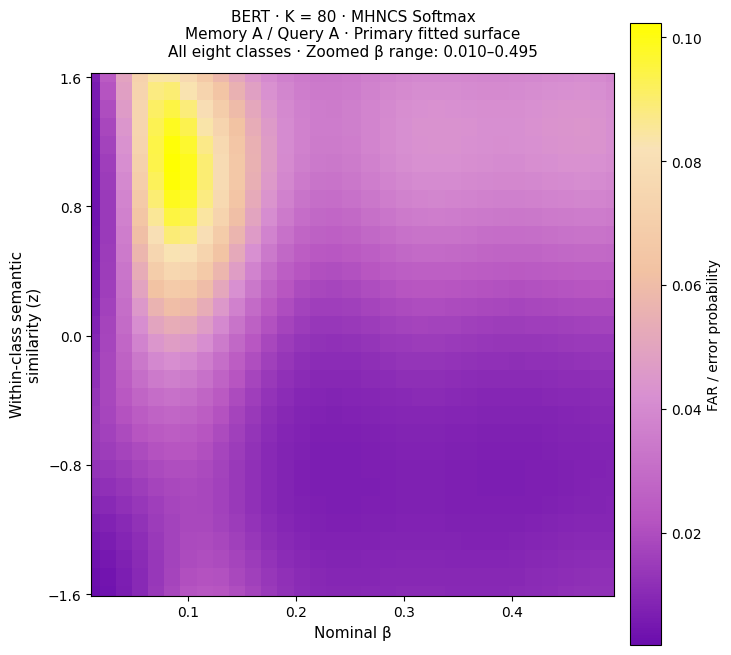

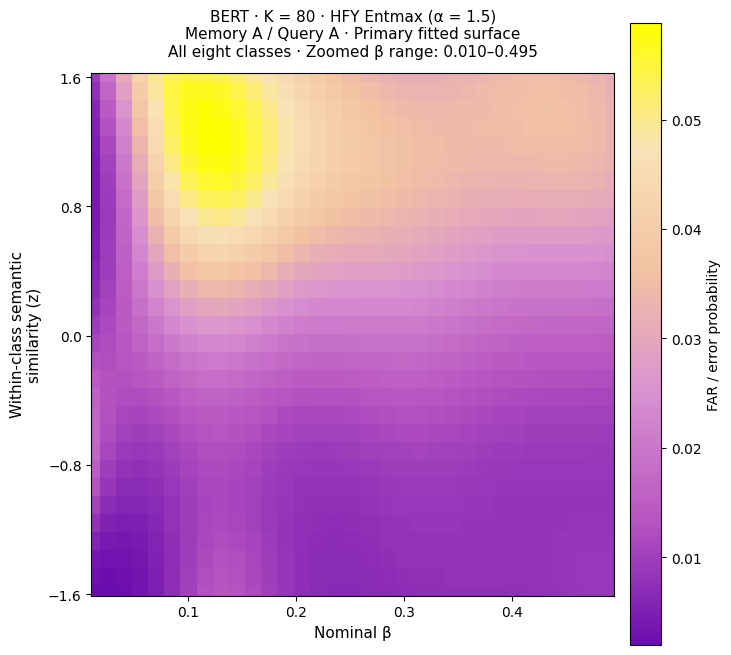

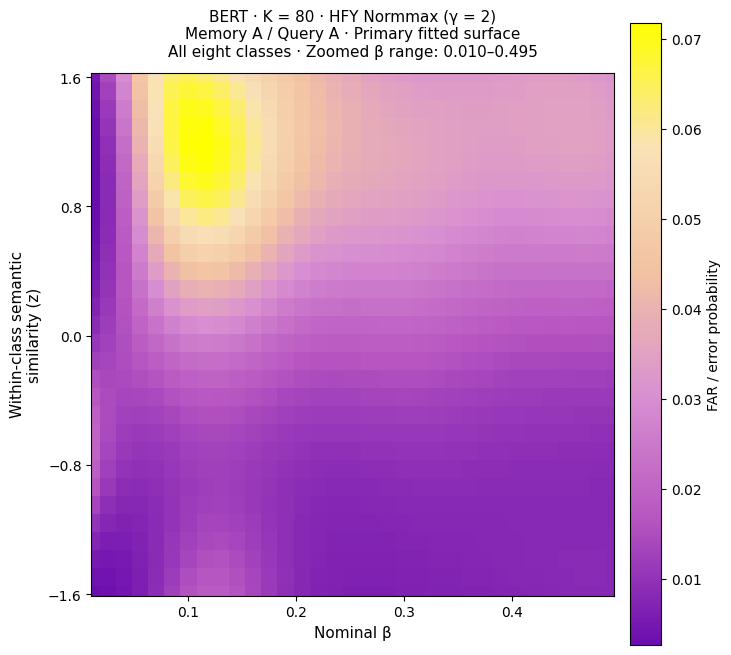

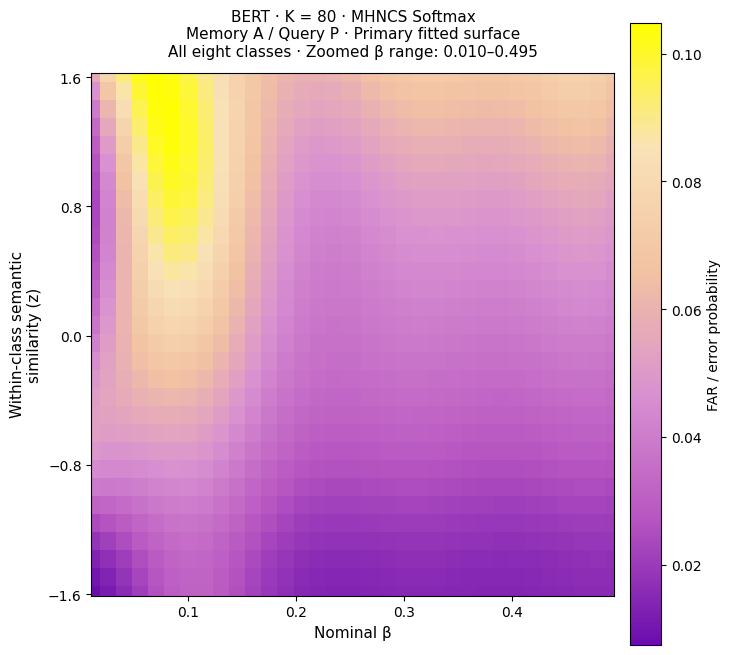

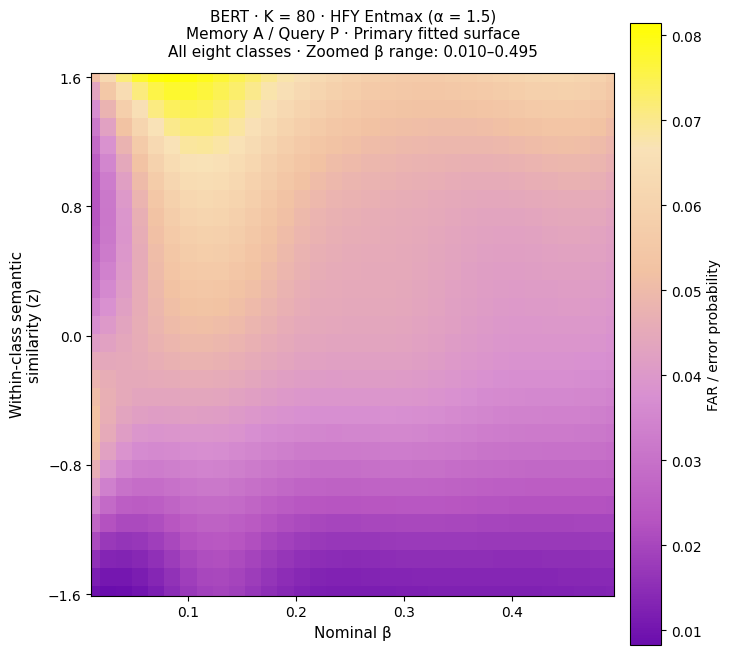

...

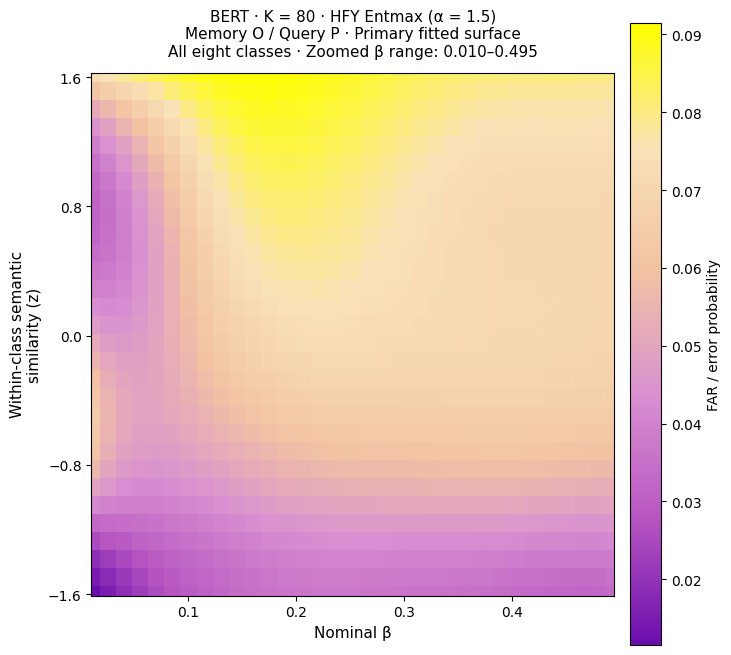

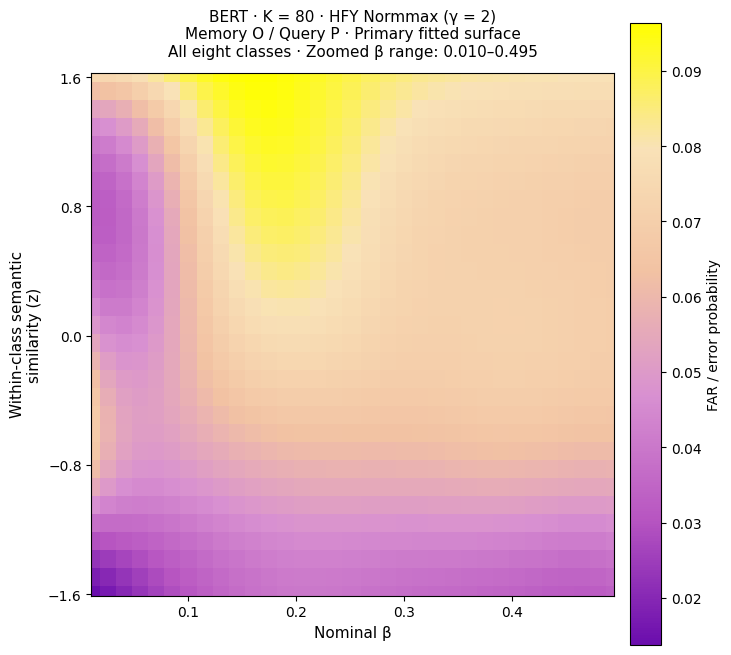

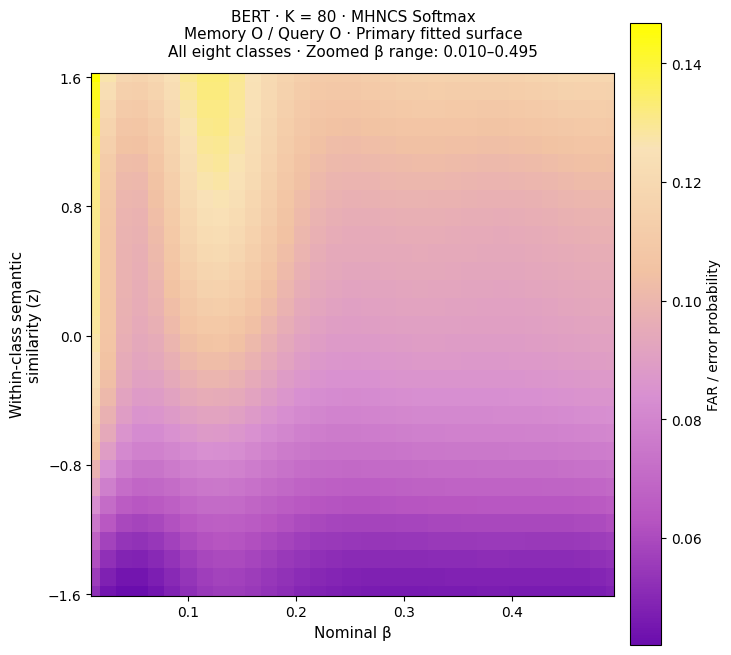

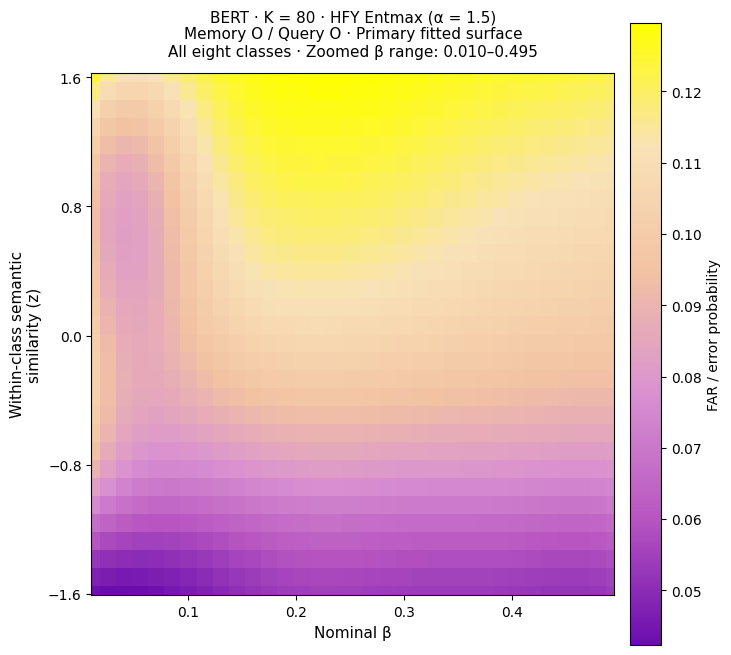

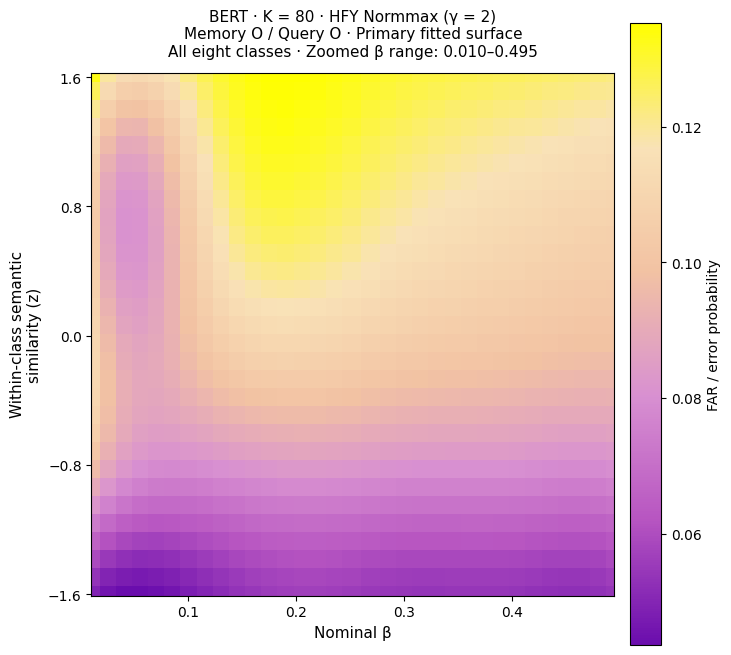

In [5]:
FIGURAS_PRINCIPALES = regenerar_heatmaps(kinds=("primary",), cases=("FULL",), show=True)

## 5. Anexos y sensibilidad

Exporta superficies empíricas FULL y LOCO, reajustes LOCO del modelo principal y el modelo alternativo FULL y LOCO. Solo dibuja resultados guardados.

En total, las secciones 4 y 5 generan 729 superficies: 243 empíricas, 243 del modelo principal y 243 del alternativo. Dos vistas y PNG/PDF producen 2.916 archivos. La exportación puede tardar varios minutos; no se muestran todos en pantalla.

In [6]:
FIGURAS_EMPIRICAS = regenerar_heatmaps(kinds=("empirical",))
FIGURAS_LOCO = regenerar_heatmaps(kinds=("primary",), cases=figs.CASES[1:])
#FIGURAS_ALTERNATIVAS = regenerar_heatmaps(kinds=("sensitivity",))
print("Figures saved to:", FIGURES.output_root)

Figures saved to: C:\Users\jisaa\Documents\ProyectoTesis\EstudioContextual\ExperimentoContextual\SalidasRevision\Figuras


## 6. Robustez y contrastes guardados

Se distinguen LOCO empírico (reagregación), LOCO del modelo (reajustes ya calculados) y sensibilidad a la especificación alternativa. Se recuperan los contrastes pareados y las interacciones.

In [7]:
display(RESULTS.tables["robustness"])
display(RESULTS.tables["empirical_contrasts"])
display(RESULTS.tables["statistical_contrasts"])

,candidate,arm,network,scope,n_LOCO,n_classes,FULL_T1T2,LOCO_T1T2_passed,R_T1T2,T1_FULL,...,T2_FULL,T2_LOCO_passed,T2_worst_signed_margin,T2_worst_omission,T2_robust,T3_FULL,T3_LOCO_passed,T3_worst_signed_margin,T3_worst_omission,T3_robust
0,S_TENSOR_SHARED__ridge_1e-04,AA,mhncs_softmax,empirical,8,8,True,7,False,0.018016,...,-0.032927,7,-0.009330,apple,False,-0.000543,6,-0.019493,apple,False
1,S_TENSOR_SHARED__ridge_1e-04,AA,mhncs_softmax,matched5,8,8,True,7,False,0.015896,...,-0.037582,7,-0.012788,apple,False,-0.014367,7,-0.016359,apple,False
2,S_TENSOR_SHARED__ridge_1e-04,AA,mhncs_softmax,grid30,8,8,True,7,False,0.014958,...,-0.036286,7,-0.011805,apple,False,-0.013680,7,-0.014424,apple,False
3,S_TENSOR_SHARED__ridge_1e-04,AA,hfy_entmax_a15,empirical,8,8,True,7,False,0.014329,...,-0.002856,7,-0.008654,apple,False,-0.002262,7,-0.008972,apple,False
4,S_TENSOR_SHARED__ridge_1e-04,AA,hfy_entmax_a15,matched5,8,8,True,7,False,0.012609,...,-0.004342,7,-0.012012,apple,False,-0.003696,7,-0.010289,apple,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,H_BETA_LINEAR_Z__ridge_1e-01,OO,hfy_entmax_a15,matched5,8,8,False,1,False,0.013333,...,0.016357,1,-0.026366,skunk,False,0.007337,0,-0.009423,jellyfish,False
158,H_BETA_LINEAR_Z__ridge_1e-01,OO,hfy_entmax_a15,grid30,8,8,False,0,False,0.012726,...,0.016276,1,-0.026271,skunk,False,0.007309,0,-0.009301,jellyfish,False
159,H_BETA_LINEAR_Z__ridge_1e-01,OO,hfy_normmax_g2,empirical,8,8,False,1,False,0.021998,...,0.011661,1,-0.024172,skunk,False,0.004364,0,-0.011357,canoe,False
160,H_BETA_LINEAR_Z__ridge_1e-01,OO,hfy_normmax_g2,matched5,8,8,False,1,False,0.013735,...,0.009074,1,-0.020275,skunk,False,0.006591,0,-0.008916,jellyfish,False


,network,case,omitted_label,contrast,scope,T1_delta,T1_signed_improvement,T1_reference,T1_target,T1_reference_pass,...,T2_reference,T2_target,T2_reference_pass,T2_target_pass,T3_delta,T3_signed_improvement,T3_reference,T3_target,T3_reference_pass,T3_target_pass
0,mhncs_softmax,FULL,NaN,PP-AA,empirical,-0.001186,-0.001186,0.018016,0.016830,True,...,-0.032927,-0.033352,True,True,0.023492,-0.023492,-0.000543,0.022949,True,False
1,mhncs_softmax,FULL,NaN,OO-AA,empirical,0.003805,0.003805,0.018016,0.021821,True,...,-0.032927,-0.023801,True,True,-0.005678,0.005678,-0.000543,-0.006221,True,True
2,mhncs_softmax,FULL,NaN,PA-AA,empirical,-0.002286,-0.002286,0.018016,0.015729,True,...,-0.032927,-0.035879,True,True,-0.001768,0.001768,-0.000543,-0.002311,True,True
3,mhncs_softmax,FULL,NaN,OA-AA,empirical,0.001194,0.001194,0.018016,0.019210,True,...,-0.032927,-0.000758,True,True,0.023439,-0.023439,-0.000543,0.022896,True,False
4,mhncs_softmax,FULL,NaN,AP-AA,empirical,0.000604,0.000604,0.018016,0.018619,True,...,-0.032927,-0.025817,True,True,0.023094,-0.023094,-0.000543,0.022550,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,hfy_normmax_g2,L07,skunk,OA-AA,empirical,0.001303,0.001303,0.018891,0.020194,True,...,-0.012429,0.038603,True,False,0.016868,-0.016868,-0.007776,0.009091,True,False
212,hfy_normmax_g2,L07,skunk,AP-AA,empirical,-0.001229,-0.001229,0.018891,0.017663,True,...,-0.012429,-0.014106,True,True,0.015523,-0.015523,-0.007776,0.007747,True,False
213,hfy_normmax_g2,L07,skunk,AO-AA,empirical,0.002382,0.002382,0.018891,0.021273,True,...,-0.012429,-0.025898,True,True,0.003791,-0.003791,-0.007776,-0.003985,True,True
214,hfy_normmax_g2,L07,skunk,P interaction,empirical,-0.000172,-0.000172,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.005030,-0.005030,NaN,NaN,NaN,NaN


,model,candidate,network,case,omitted_label,contrast,scope,T1_delta,T1_signed_improvement,T1_reference,...,T2_reference,T2_target,T2_reference_pass,T2_target_pass,T3_delta,T3_signed_improvement,T3_reference,T3_target,T3_reference_pass,T3_target_pass
0,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,FULL,NaN,PP-AA,empirical,-0.001186,-0.001186,0.018016,...,-0.032927,-0.033352,True,True,0.023492,-0.023492,-0.000543,0.022949,True,False
1,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,FULL,NaN,OO-AA,empirical,0.003805,0.003805,0.018016,...,-0.032927,-0.023801,True,True,-0.005678,0.005678,-0.000543,-0.006221,True,True
2,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,FULL,NaN,PA-AA,empirical,-0.002286,-0.002286,0.018016,...,-0.032927,-0.035879,True,True,-0.001768,0.001768,-0.000543,-0.002311,True,True
3,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,FULL,NaN,OA-AA,empirical,0.001194,0.001194,0.018016,...,-0.032927,-0.000758,True,True,0.023439,-0.023439,-0.000543,0.022896,True,False
4,PRIMARY,S_TENSOR_SHARED__ridge_1e-04,mhncs_softmax,FULL,NaN,AP-AA,empirical,0.000604,0.000604,0.018016,...,-0.032927,-0.025817,True,True,0.023094,-0.023094,-0.000543,0.022550,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1291,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,L07,skunk,OA-AA,grid30,0.003248,0.003248,0.010912,...,-0.017488,0.025729,True,False,0.018381,-0.018381,-0.013262,0.005120,True,False
1292,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,L07,skunk,AP-AA,grid30,-0.001493,-0.001493,0.010912,...,-0.017488,-0.018357,True,True,0.004789,-0.004789,-0.013262,-0.008473,True,True
1293,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,L07,skunk,AO-AA,grid30,0.001164,0.001164,0.010912,...,-0.017488,-0.020607,True,True,0.005462,-0.005462,-0.013262,-0.007799,True,True
1294,SENSITIVITY,H_BETA_LINEAR_Z__ridge_1e-01,hfy_normmax_g2,L07,skunk,P interaction,grid30,0.000572,0.000572,NaN,...,NaN,NaN,NaN,NaN,0.006436,-0.006436,NaN,NaN,NaN,NaN


## Volver a dibujar después de editar

Ejecutar después de cargar RESULTS y definir FIGURES. La recarga no modifica tu configuración. Para exportar todo usa regenerar_heatmaps(); para una revisión rápida, usa solo FULL.

In [8]:
importlib.reload(figs)
# Descomenta cuando quieras volver a dibujar:
# regenerar_heatmaps(kinds=("primary",), cases=("FULL",), show=True)

<module 'contextual_guardado' from 'C:\\Users\\jisaa\\Documents\\ProyectoTesis\\EstudioContextual\\ExperimentoContextual\\CodigoComun\\contextual_guardado.py'>

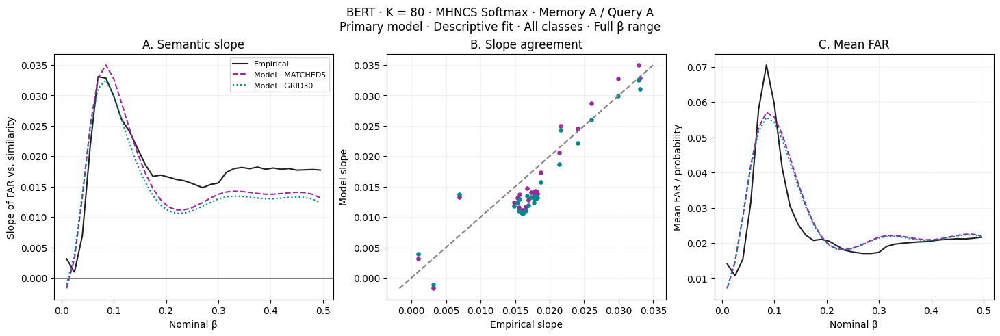

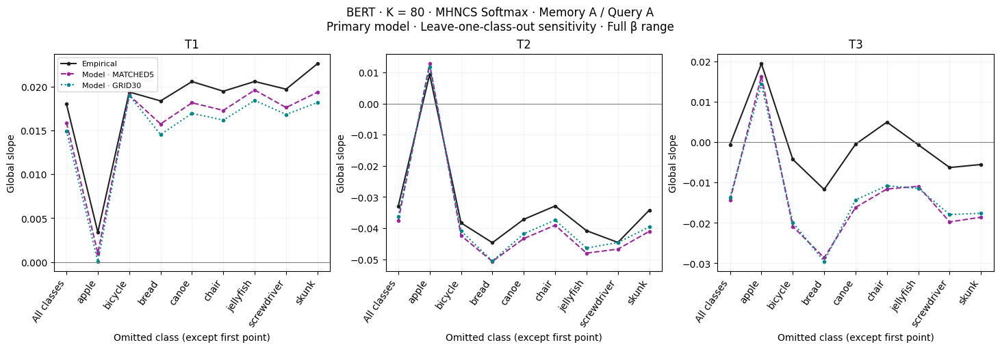

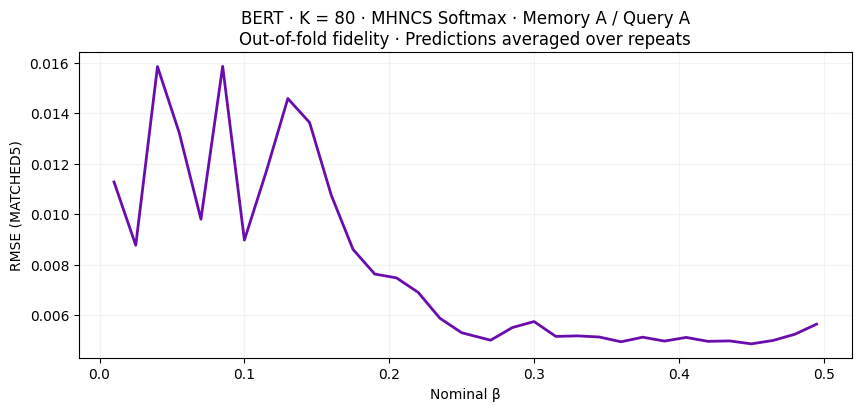

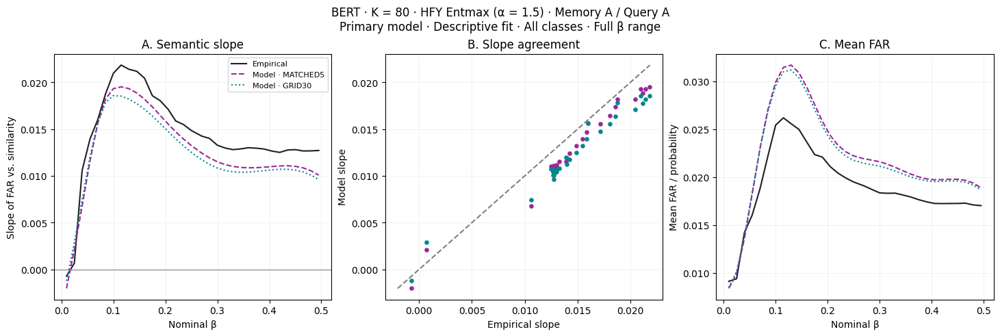

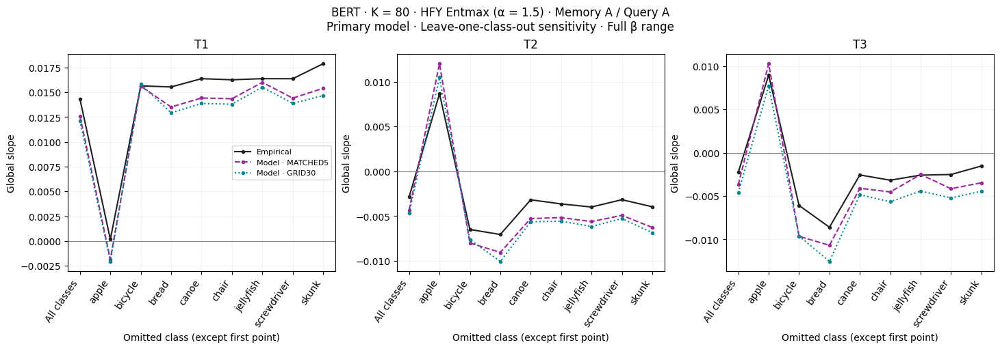

...

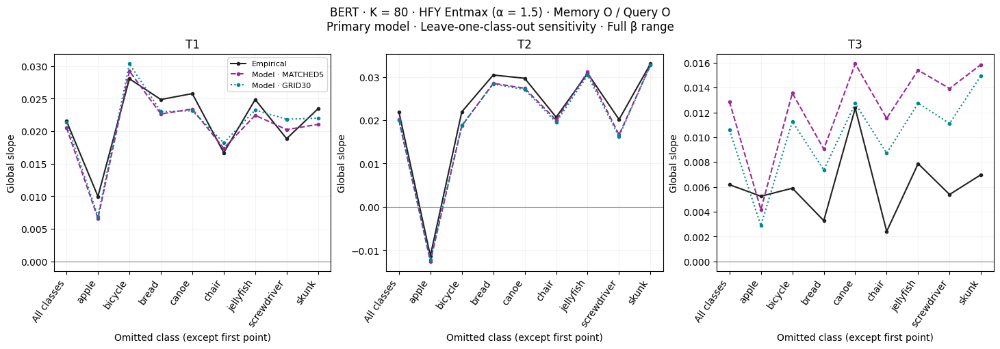

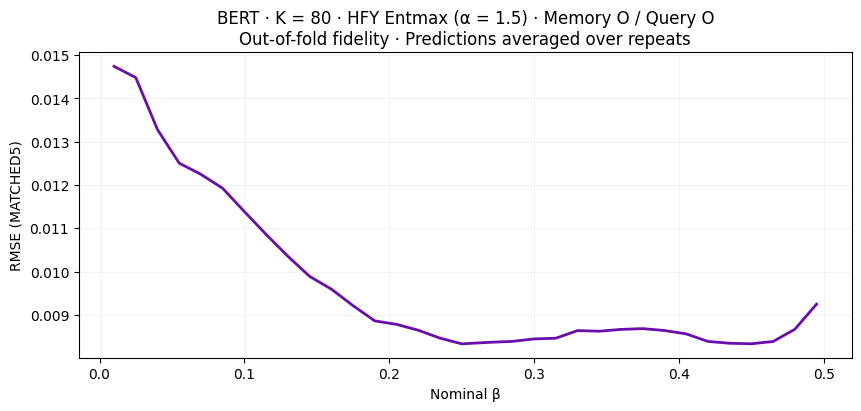

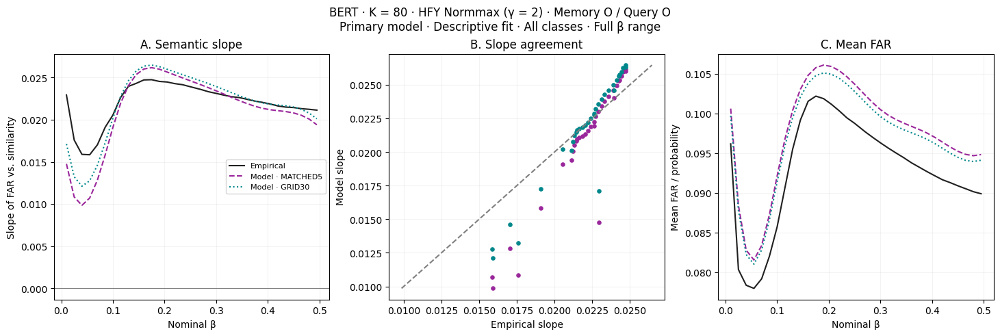

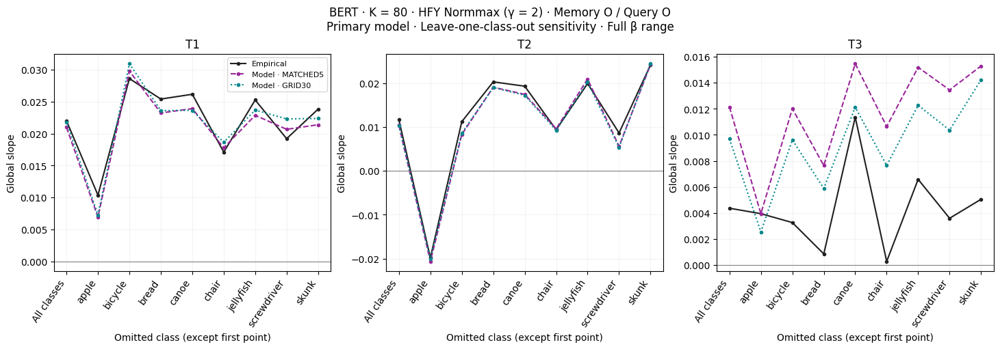

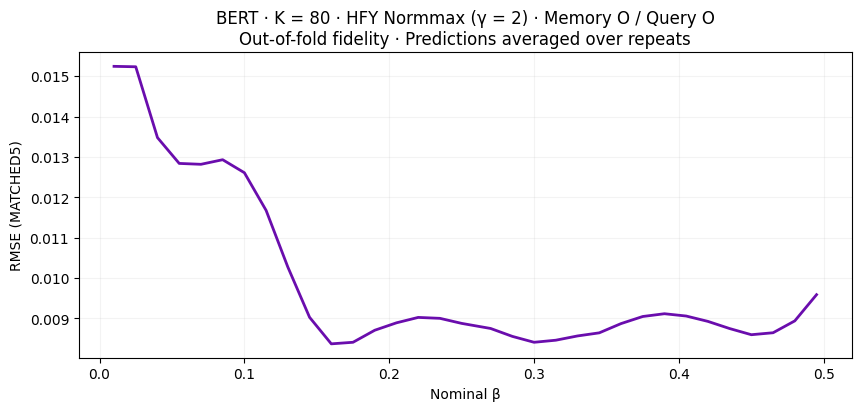

In [9]:
from diagnosticos_contextual import plot_diagnostics

DIAGNOSTICOS = plot_diagnostics(RESULTS, FIGURES, show=True)

In [12]:
# CELDA 1 — Funciones comunes para las figuras compuestas.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_PANELES = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_panels",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_PANELES.set_bad("#DDDDDD")
_REDES_PANELES = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_PANELES = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_panel(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_panel(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_paneles(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_panel_compuesto(filas, titulo, destino, nombre, beta_range=(0.01, 0.15),
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) not in (1, 3) or any(len(f) != 3 for f in filas):
        raise ValueError("Usa una fila de tres paneles o tres filas de tres paneles.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_panel(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_panel(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_paneles(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.00
        espacio_x, espacio_y, barra_ancho = 0.38, 0.55, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_panel(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_PANELES, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=10, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · All eight classes\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


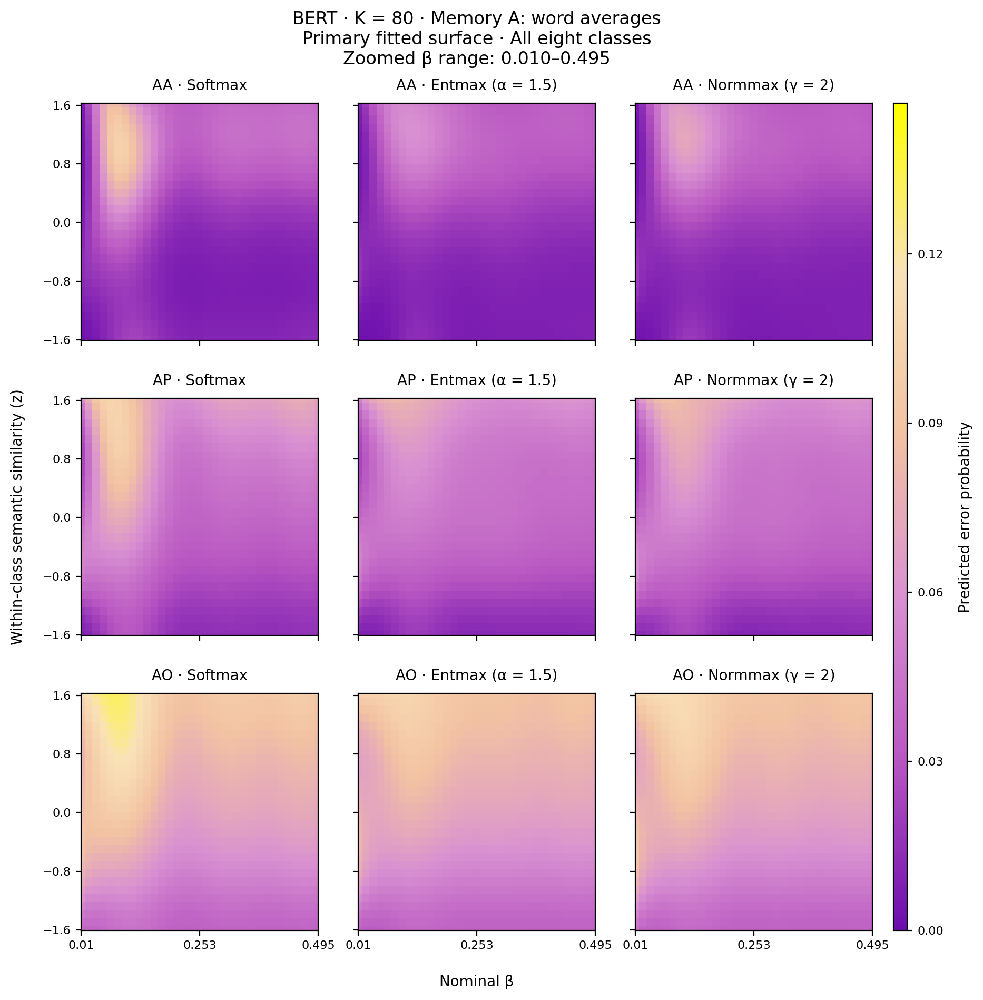

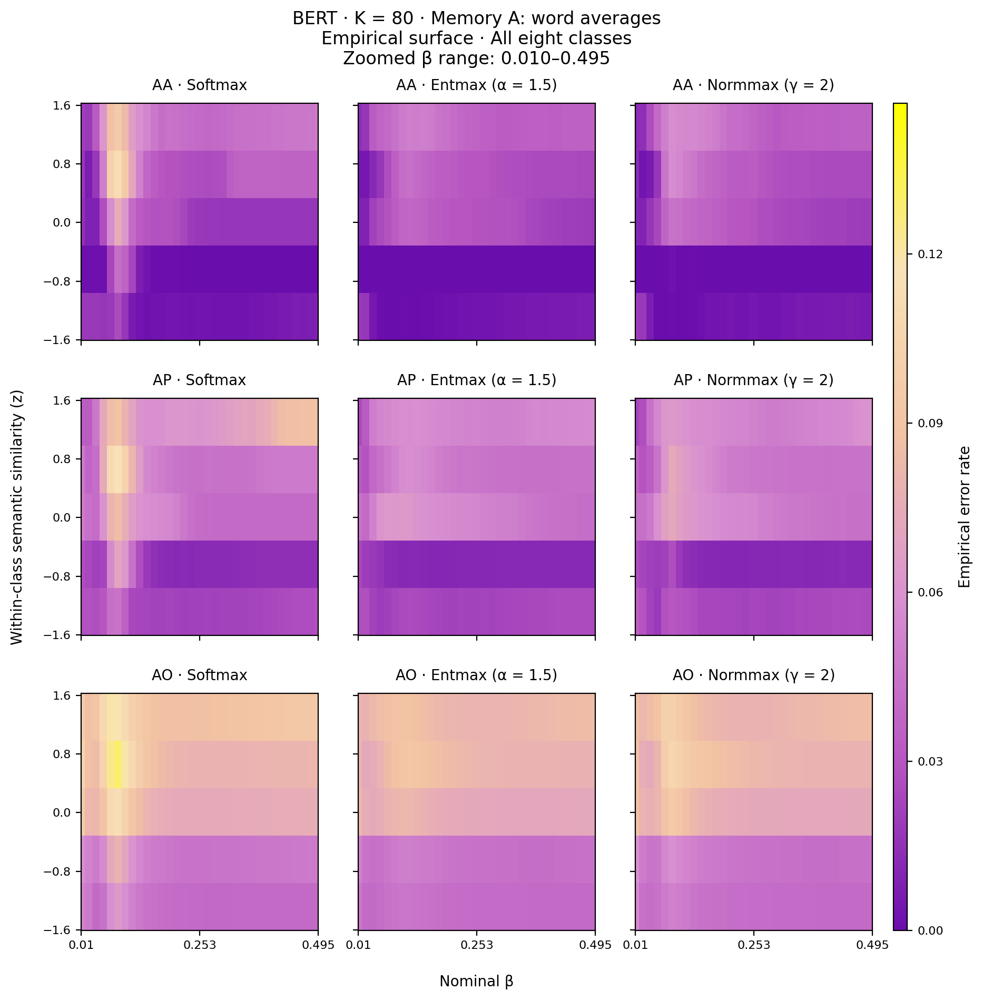

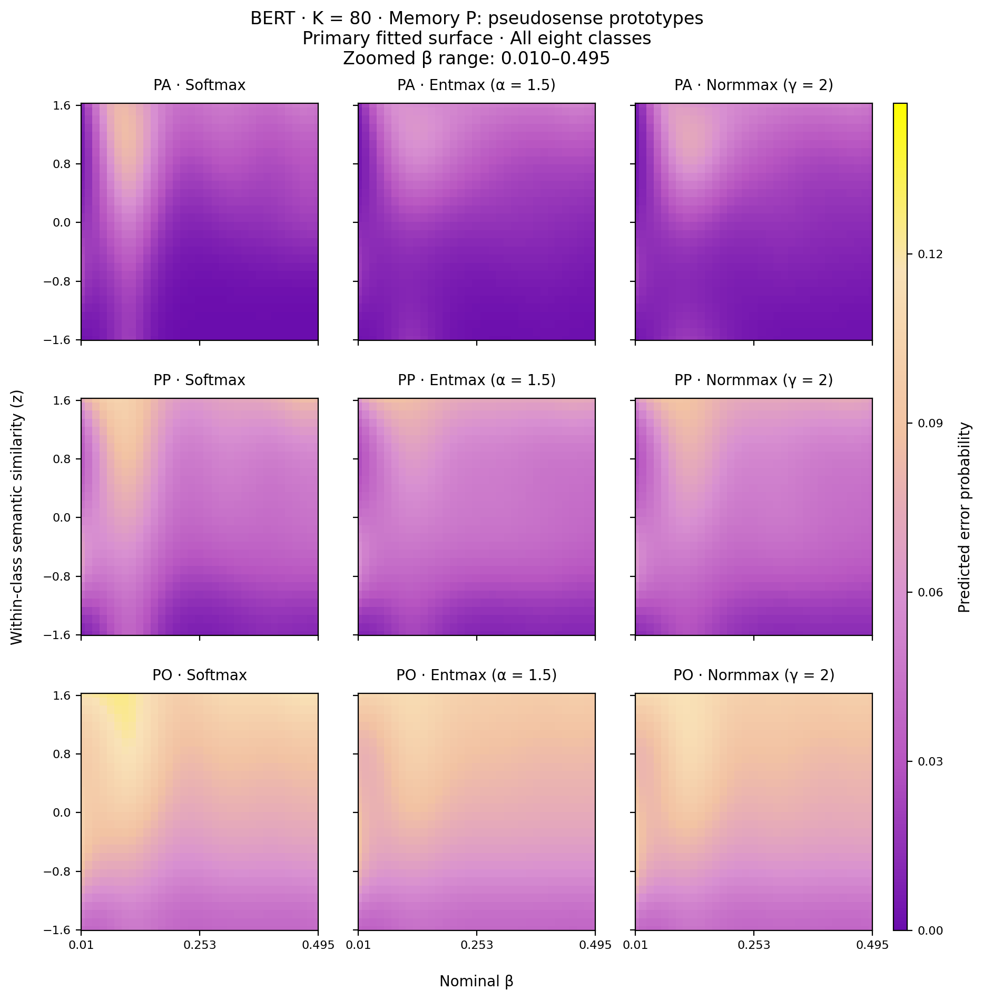

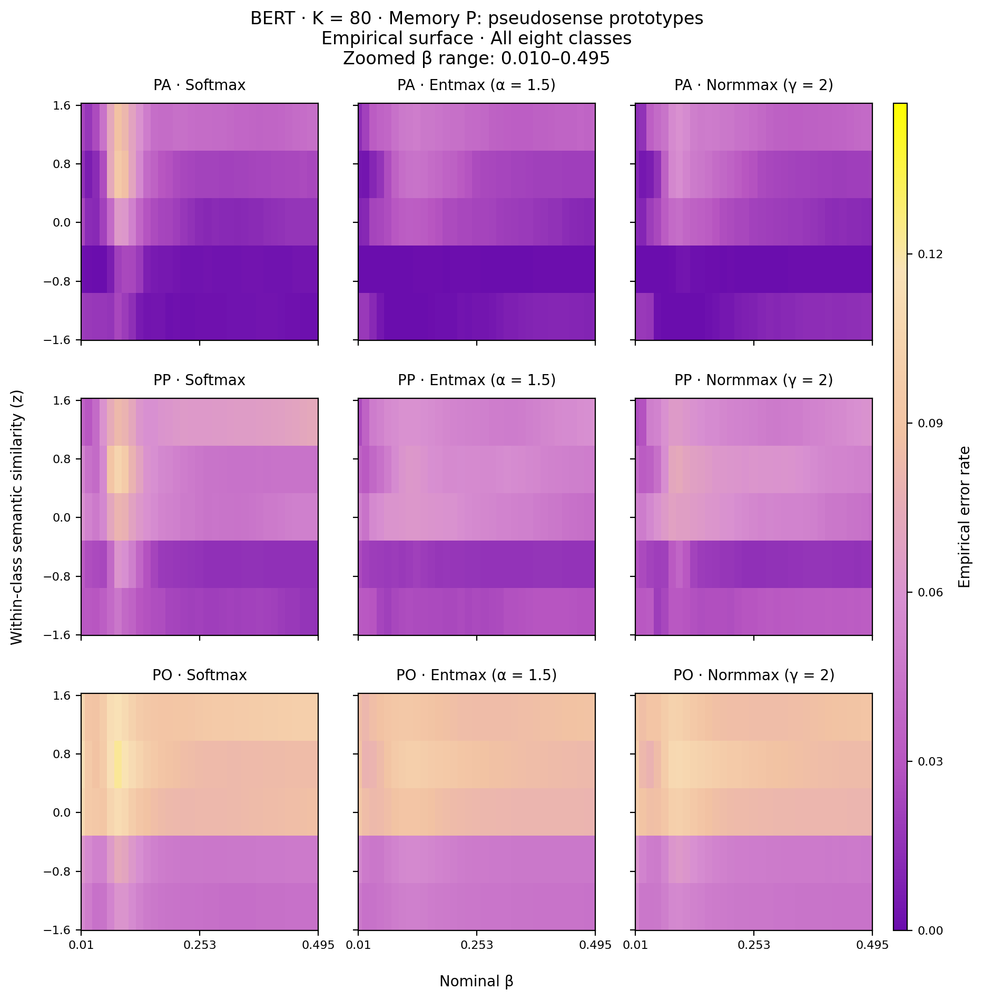

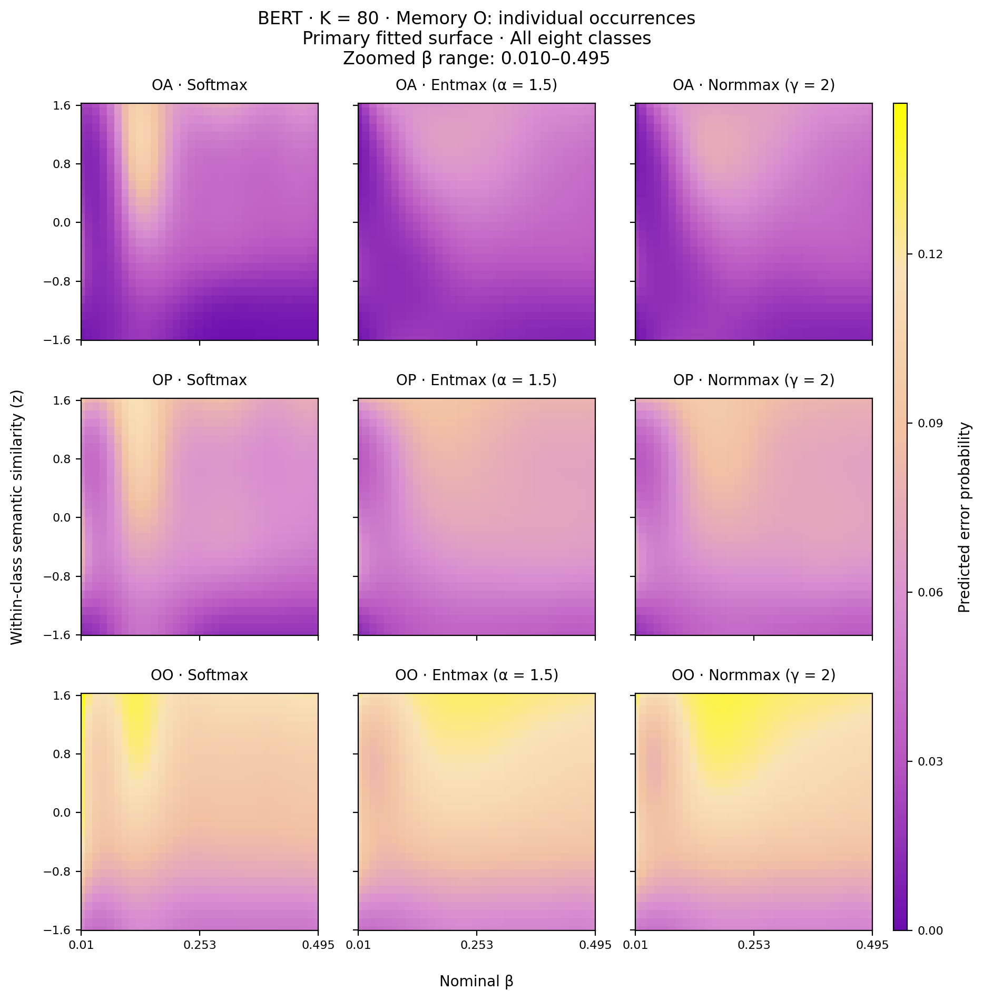

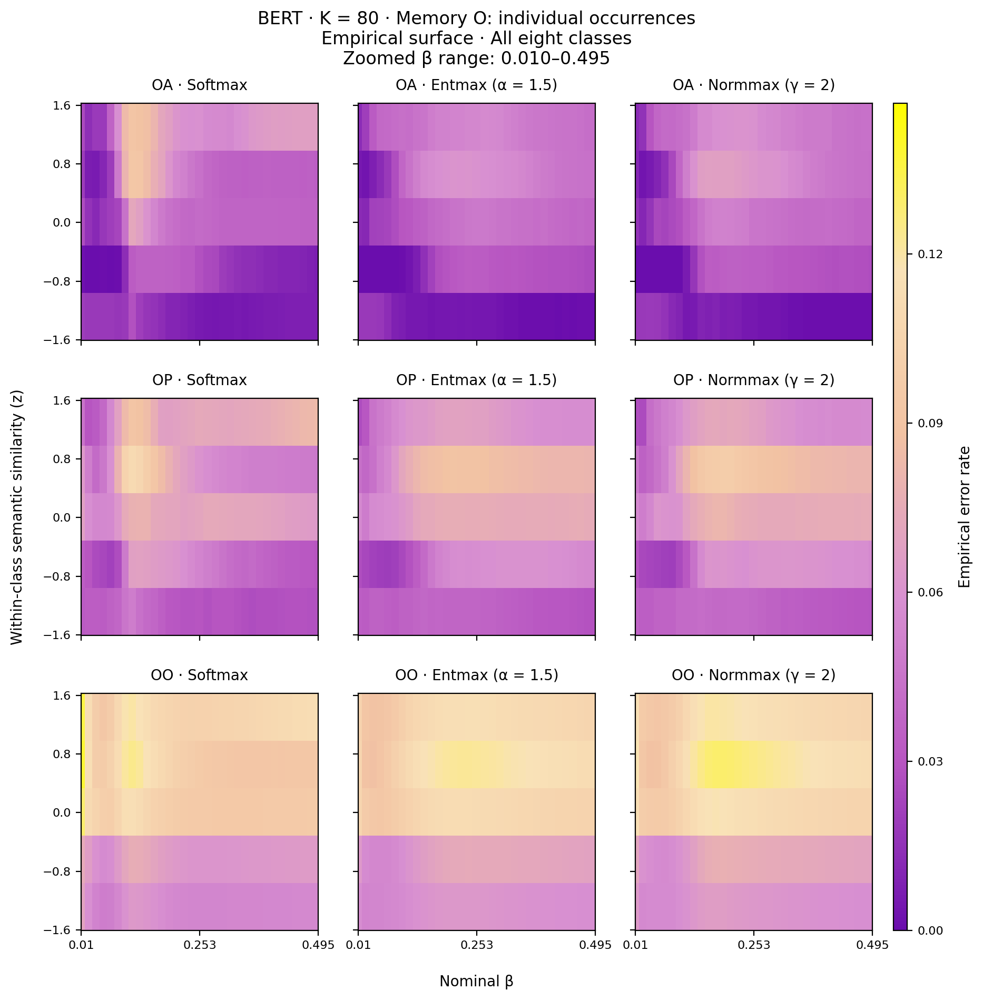

Figuras compuestas: C:\Users\jisaa\Documents\ProyectoTesis\EstudioContextual\ExperimentoContextual\SalidasRevision\Figuras\PanelesCompuestos


In [19]:
# CELDA 2 — Figuras contextuales FULL: modelo y empíricas, nueve heatmaps por imagen.
# Ejecutar después de cargar/verificar RESULTS y de definir FIGURES.

# EDITABLE: un intervalo por imagen, independiente entre tipos y memorias.
BETAS_CONTEXTUALES = {  # MODELO
    "A": (0.01, 0.495),  # filas AA, AP, AO
    "P": (0.01, 0.495),  # filas PA, PP, PO
    "O": (0.01, 0.495),  # filas OA, OP, OO
}
BETAS_EMPIRICOS_CONTEXTUALES = {
    "A": (0.01, 0.495), "P": (0.01, 0.495), "O": (0.01, 0.495),
}
TIPOS_CONTEXTUALES = ("model", "empirical")  # Solo empíricas: ("empirical",)
# None calcula una escala común a las 54 superficies FULL (modelo + empíricas).
# También puedes fijar (0.0, 1.0), por ejemplo.
ESCALA_CONTEXTUAL_COMUN = None
# Opcional: escala por memoria, compartida por su figura empírica y su modelo.
COLORES_CONTEXTUALES = {"A": None, "P": None, "O": None}
TAMANO_PANEL_CONTEXTUAL = 2.25  # pulgadas por lado de CADA heatmap
DPI_CONTEXTUAL = 200
GUARDAR_COMPLETAS_CONTEXTUAL = True

if not callable(getattr(globals().get("RESULTS"), "surface", None)):
    raise RuntimeError("Ejecuta primero la carga de RESULTS de EstudioContextual.ipynb.")
if not TIPOS_CONTEXTUALES or not set(TIPOS_CONTEXTUALES) <= {"model", "empirical"}:
    raise ValueError("Selecciona model, empirical o ambos.")
SUPERFICIES_CONTEXTUALES = {
    (tipo, memoria + consulta, red): _preparar_superficie_panel(
        RESULTS.surface(memoria + consulta, red, case="FULL",
                        kind="primary" if tipo == "model" else "empirical", representation="grid30")
    )
    for tipo in ("model", "empirical") for memoria in "APO" for consulta in "APO" for red in range(3)
}
# En el lector del proyecto, kind="empirical" conserva sus 5 filas originales;
# representation="grid30" solo selecciona la malla para kind="primary".
limites_comunes = _escala_paneles(list(SUPERFICIES_CONTEXTUALES.values()), ESCALA_CONTEXTUAL_COMUN)
SALIDA_PANELES_CONTEXTUALES = Path(FIGURES.output_root) / "PanelesCompuestos"
NOMBRES_MEMORIA = {"A": "word averages", "P": "pseudosense prototypes", "O": "individual occurrences"}
REGISTRO_PANELES_CONTEXTUALES = []
for memoria in BETAS_CONTEXTUALES:
    if memoria not in NOMBRES_MEMORIA:
        raise ValueError("Las memorias disponibles son A, P y O.")
    for tipo in TIPOS_CONTEXTUALES:
        intervalo = (BETAS_CONTEXTUALES if tipo == "model" else BETAS_EMPIRICOS_CONTEXTUALES)[memoria]
        filas = [
            [(f"{memoria + consulta} · {titulo}", SUPERFICIES_CONTEXTUALES[tipo, memoria + consulta, red])
             for red, titulo in enumerate(_TITULOS_REDES_PANELES)]
            for consulta in "APO"
        ]
        REGISTRO_PANELES_CONTEXTUALES += guardar_panel_compuesto(
            filas, titulo=f"BERT · K = 80 · Memory {memoria}: {NOMBRES_MEMORIA[memoria]}",
            destino=SALIDA_PANELES_CONTEXTUALES, nombre=f"bert_k80_memory_{memoria}_{tipo}_FULL",
            beta_range=intervalo,
            color_limits=limites_comunes if COLORES_CONTEXTUALES[memoria] is None else COLORES_CONTEXTUALES[memoria],
            panel_inches=TAMANO_PANEL_CONTEXTUAL, dpi=DPI_CONTEXTUAL,
            guardar_completa=GUARDAR_COMPLETAS_CONTEXTUAL,
            surface_kind=tipo, y_edges=RESULTS.geometry["edges"] if tipo == "empirical" else None,
        )
print("Figuras compuestas:", SALIDA_PANELES_CONTEXTUALES)


In [20]:
# CELDA 1 — Funciones para comparaciones FULL frente a una omisión LOCO.
# Copiar esta celda al notebook correspondiente; solo dibuja superficies ya guardadas.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Image

_PALETA_LOCO = LinearSegmentedColormap.from_list(
    "thesis_purple_yellow_locos",
    ["#6A0DAD", "#B755C1", "#D890D1", "#F2C2A3", "#F9E2B7", "#FFFF00"],
)
_PALETA_LOCO.set_bad("#DDDDDD")
_REDES_LOCO = ("mhncs_softmax", "hfy_entmax_a15", "hfy_normmax_g2")
_TITULOS_REDES_LOCO = ("Softmax", "Entmax (α = 1.5)", "Normmax (γ = 2)")


def _preparar_superficie_loco(s):
    s = s.copy(deep=True)
    s.index = s.index.astype(float)
    s.columns = s.columns.astype(float)
    s = s.sort_index().sort_index(axis=1)
    if min(s.shape) < 2 or s.index.has_duplicates or s.columns.has_duplicates:
        raise ValueError("La superficie debe tener al menos dos coordenadas distintas por eje.")
    if not np.isfinite(s.index).all() or not np.isfinite(s.columns).all():
        raise ValueError("Coordenadas no finitas.")
    if not np.isfinite(s.to_numpy()).all():
        raise ValueError("La superficie FULL contiene valores no finitos.")
    return s


def _bordes_loco(x):
    x = np.asarray(x, float)
    return np.r_[x[0] - (x[1] - x[0])/2, (x[:-1] + x[1:])/2,
                 x[-1] + (x[-1] - x[-2])/2]


def _escala_loco(superficies, limites=None):
    minimo = min(float(s.to_numpy().min()) for s in superficies)
    maximo = max(float(s.to_numpy().max()) for s in superficies)
    if limites is None:
        return (minimo, maximo) if minimo < maximo else (0.0, 1.0)
    lo, hi = map(float, limites)
    if not np.isfinite([lo, hi]).all() or not 0 <= lo < hi <= 1:
        raise ValueError("Los límites de color deben cumplir 0 <= mínimo < máximo <= 1.")
    return lo, hi


def guardar_comparacion_loco(filas, titulo, destino, nombre, beta_range=None,
                            color_limits=None, panel_inches=2.25, dpi=200,
                            guardar_completa=True, mostrar=True, surface_kind="model", y_edges=None):
    """filas: lista de filas; cada fila contiene tres pares (título, DataFrame).

    El recorte solo modifica xlim. No se interpola, suaviza ni reajusta el modelo.
    La escala de color se calcula en el dominio COMPLETO y se mantiene en ambas vistas.
    """
    if len(filas) != 2 or any(len(f) != 3 for f in filas):
        raise ValueError("Usa dos filas: FULL y una omisión; tres redes por fila.")
    if panel_inches < 1.8 or dpi < 72:
        raise ValueError("Usa panel_inches >= 1.8 y dpi >= 72 para conservar legibilidad.")
    filas = [[(t, _preparar_superficie_loco(s)) for t, s in fila] for fila in filas]
    superficies = [s for fila in filas for _, s in fila]
    referencia = superficies[0]
    for s in superficies[1:]:
        np.testing.assert_allclose(s.index, referencia.index, rtol=0, atol=1e-12)
        np.testing.assert_allclose(s.columns, referencia.columns, rtol=0, atol=1e-12)
    beta = referencia.columns.to_numpy(float)
    z = referencia.index.to_numpy(float)
    if surface_kind not in ("model", "empirical"):
        raise ValueError("surface_kind debe ser model o empirical.")
    if surface_kind == "empirical":
        if y_edges is None:
            raise ValueError("La superficie empírica necesita los bordes originales de sus cinco intervalos.")
        bordes_y = np.asarray(y_edges, float)
        if (len(z) != 5 or bordes_y.shape != (6,) or not np.isfinite(bordes_y).all()
                or not np.all(np.diff(bordes_y) > 0)
                or not np.all((z > bordes_y[:-1]) & (z < bordes_y[1:]))):
            raise ValueError("Bordes empíricos incompatibles con los cinco intervalos guardados.")
        limites_y = (float(bordes_y[0]), float(bordes_y[-1]))
        descripcion_superficie = "Empirical surface (LOCO reaggregation)"
        etiqueta_color = "Empirical error rate"
    else:
        if len(z) != 30:
            raise ValueError("La superficie del modelo debe ser GRID30.")
        bordes_y = _bordes_loco(z)
        limites_y = (float(z.min()), float(z.max()))
        descripcion_superficie = "Primary fitted surface (LOCO refit)"
        etiqueta_color = "Predicted error probability"
    completo = (float(beta.min()), float(beta.max()))
    seleccion = completo if beta_range is None else tuple(map(float, beta_range))
    if (len(seleccion) != 2 or not np.isfinite(seleccion).all()
            or seleccion[0] >= seleccion[1]
            or seleccion[0] < completo[0] - 1e-12 or seleccion[1] > completo[1] + 1e-12):
        raise ValueError(f"El intervalo de beta debe quedar dentro de {completo}.")
    seleccion = (max(seleccion[0], completo[0]), min(seleccion[1], completo[1]))
    limites = _escala_loco(superficies, color_limits)
    norm = Normalize(*limites)
    valores = np.concatenate([s.to_numpy().ravel() for s in superficies])
    debajo, encima = valores.min() < limites[0], valores.max() > limites[1]
    extension = "both" if debajo and encima else "min" if debajo else "max" if encima else "neither"
    vistas = [("selected", seleccion)] if beta_range is not None else [("full", completo)]
    if guardar_completa and beta_range is not None:
        vistas.append(("full", completo))
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    registros = []
    for vista, rango in vistas:
        nfilas = len(filas)
        # Medidas físicas en pulgadas: cada área de datos mide panel_inches × panel_inches.
        izquierda, abajo, arriba = 0.70, 0.65, 1.15
        espacio_x, espacio_y, barra_ancho = 0.38, 0.75, 0.13
        ancho_datos = 3*panel_inches + 2*espacio_x
        alto_datos = nfilas*panel_inches + (nfilas-1)*espacio_y
        ancho = izquierda + ancho_datos + 0.20 + barra_ancho + 0.72
        alto = abajo + alto_datos + arriba
        with plt.rc_context({"font.size": 9, "pdf.fonttype": 42, "font.family": "DejaVu Sans"}):
            fig = plt.figure(figsize=(ancho, alto))
            try:
                ejes = []
                for i, fila in enumerate(filas):
                    for j, (subtitulo, s) in enumerate(fila):
                        x0 = izquierda + j*(panel_inches + espacio_x)
                        y0 = abajo + (nfilas-1-i)*(panel_inches + espacio_y)
                        ax = fig.add_axes([x0/ancho, y0/alto, panel_inches/ancho, panel_inches/alto])
                        im = ax.pcolormesh(_bordes_loco(beta), bordes_y, s.to_numpy(),
                                          cmap=_PALETA_LOCO, norm=norm, shading="flat", rasterized=True)
                        ax.set_xlim(*rango)
                        ax.set_ylim(*limites_y)
                        ax.set_box_aspect(1)
                        ax.set_title(subtitulo, fontsize=9, pad=9)
                        ax.set_xticks(np.linspace(*rango, 3))
                        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".rstrip("0").rstrip(".")))
                        ax.yaxis.set_major_locator(MaxNLocator(5))
                        ax.tick_params(labelsize=8, labelleft=(j == 0), labelbottom=(i == nfilas-1))
                        ejes.append(ax)
                cax = fig.add_axes([(izquierda+ancho_datos+0.20)/ancho, abajo/alto,
                                    barra_ancho/ancho, alto_datos/alto])
                cb = fig.colorbar(im, cax=cax, extend=extension)
                cb.set_label(etiqueta_color, fontsize=10, labelpad=10)
                cb.locator = MaxNLocator(5)
                cb.update_ticks()
                cb.ax.tick_params(labelsize=8)
                descripcion = "Full β range" if vista == "full" else "Zoomed β range"
                fig.text((izquierda+ancho_datos/2)/ancho, 1-0.12/alto,
                         f"{titulo}\n{descripcion_superficie} · FULL vs leave-one-class-out\n"
                         f"{descripcion}: {rango[0]:.3f}–{rango[1]:.3f}",
                         ha="center", va="top", fontsize=12)
                fig.text((izquierda+ancho_datos/2)/ancho, 0.12/alto,
                         "Nominal β", ha="center", fontsize=10)
                fig.text(0.10/ancho, (abajo+alto_datos/2)/alto,
                         "Within-class semantic similarity (z)", rotation=90,
                         ha="center", va="center", fontsize=10)
                fig.canvas.draw()
                desviacion = max(abs(ax.get_window_extent().width/ax.get_window_extent().height-1) for ax in ejes)
                if desviacion > 1e-8:
                    raise RuntimeError("Los paneles no son cuadrados.")
                tramo = "_".join(f"{v:.6g}".replace(".", "p") for v in rango)
                stem = f"{nombre}_{vista}_beta_{tramo}"
                for extension_archivo in ("png", "pdf"):
                    fig.savefig(destino/f"{stem}.{extension_archivo}", dpi=dpi,
                                bbox_inches="tight", facecolor="white")
                registro = {"name": nombre, "view": vista, "beta_range": rango,
                            "full_beta_range": completo, "color_limits": limites,
                            "n_panels": len(superficies), "max_square_deviation": desviacion,
                            "surface_kind": surface_kind, "n_similarity_rows": len(z),
                            "similarity_limits": limites_y, "similarity_edges": bordes_y.tolist(),
                            "source_surface_sha256": [hashlib.sha256(s.to_csv().encode()).hexdigest() for s in superficies],
                            "interpolation": False, "smoothing": False, "model_refitted": False,
                            "panel_labels": [t for fila in filas for t, _ in fila],
                            "trends_full_beta_range": [_tendencias_loco(s) for s in superficies]}
                (destino/f"{stem}.json").write_text(json.dumps(registro, indent=2), encoding="utf-8")
                registros.append(registro)
                if mostrar and vista == vistas[0][0]:
                    display(Image(filename=str(destino/f"{stem}.png"), width=1050))
            finally:
                plt.close(fig)
    return registros


def _tendencias_loco(surface):
    """Mismas pendientes globales del proyecto, sobre todo el dominio guardado."""
    z = surface.index.to_numpy(float)
    b = surface.columns.to_numpy(float)
    y = surface.to_numpy(float)
    z = (z-z.mean()) / np.square(z-z.mean()).sum()
    b = (b-b.mean()) / np.square(b-b.mean()).sum()
    slope = z @ y
    t = dict(T1=float(slope.mean()), T2=float((y @ b).mean()), T3=float(slope @ b))
    if np.all(y == y[0:1, :]): t.update(T1=0.0, T3=0.0)
    if np.all(y == y[:, 0:1]): t.update(T2=0.0, T3=0.0)
    return t


def _filas_loco(superficies, etiqueta):
    return [[(f"{titulo}\n{caso}", s) for titulo, s in zip(_TITULOS_REDES_LOCO, grupo)]
            for caso, grupo in zip(("FULL · All eight classes", f"Without {etiqueta} · Seven classes"), superficies)]


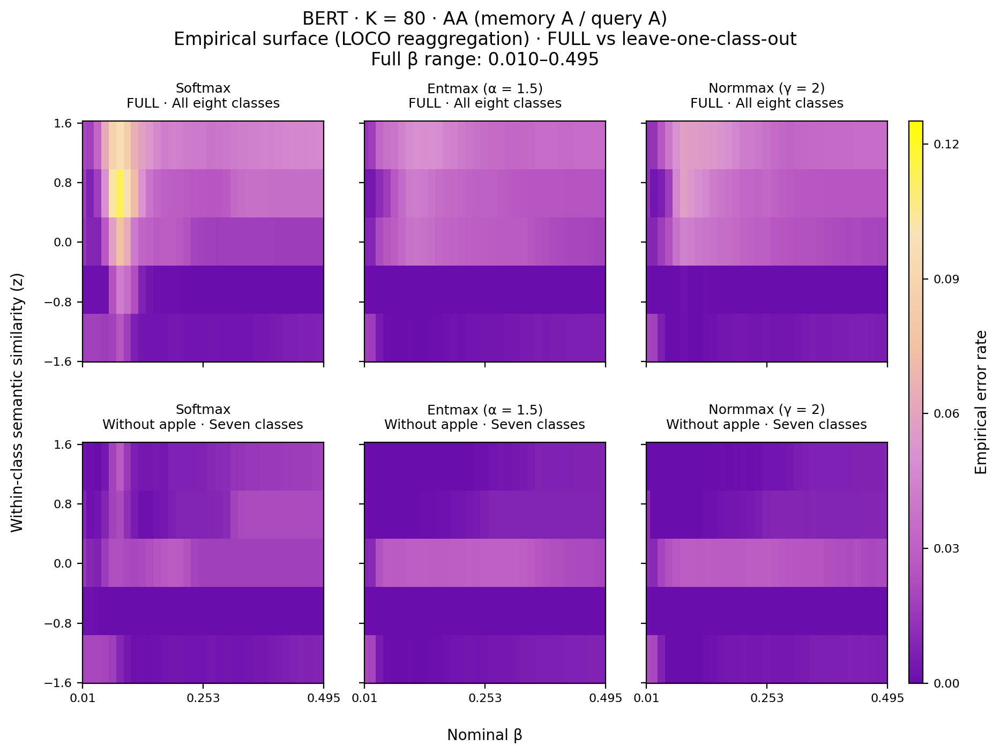

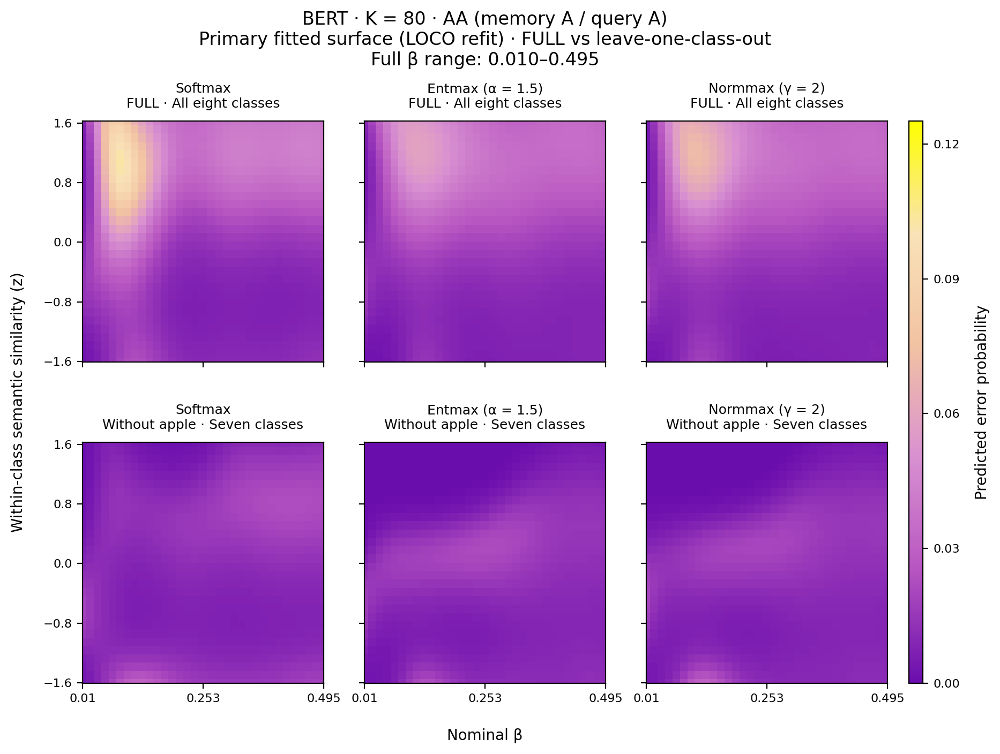

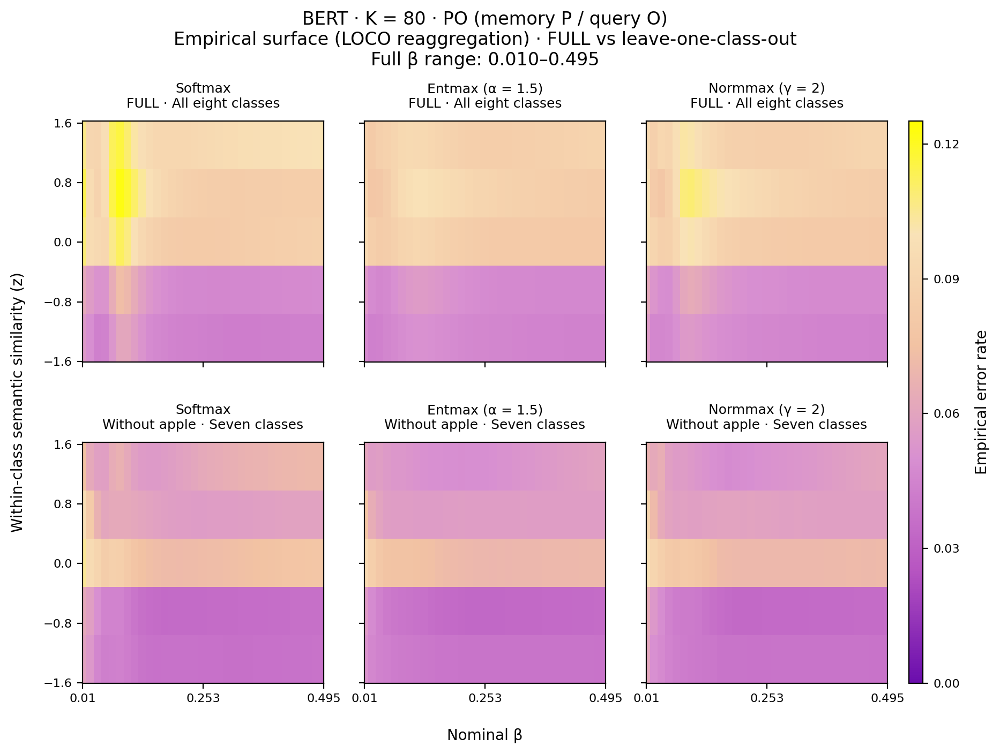

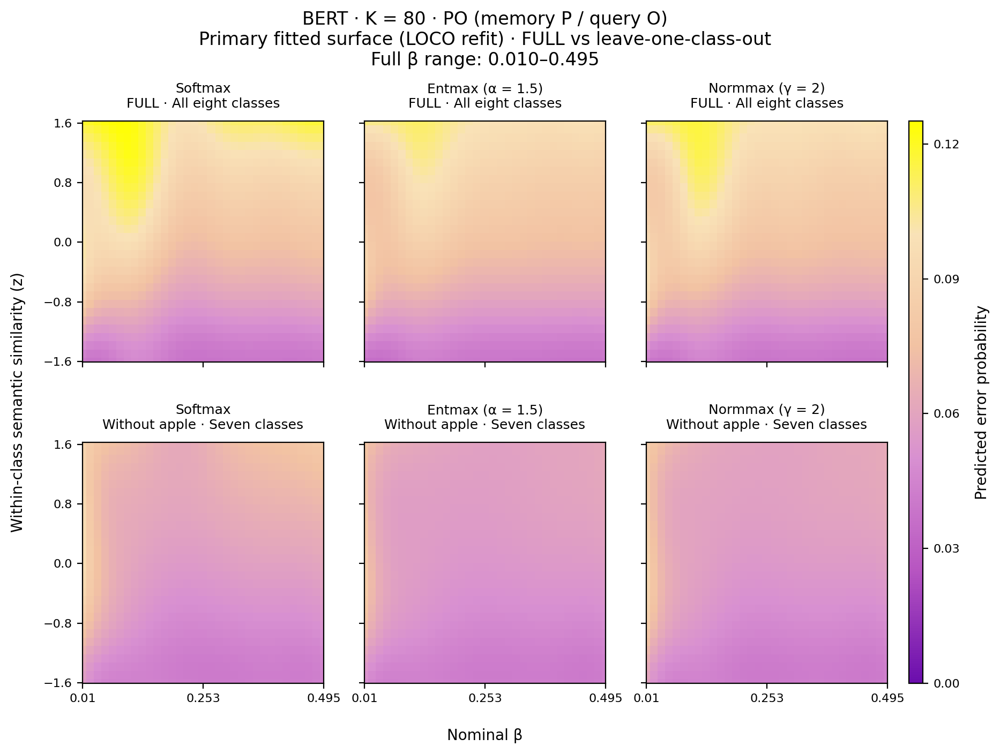

Comparaciones guardadas en: C:\Users\jisaa\Documents\ProyectoTesis\EstudioContextual\ExperimentoContextual\SalidasRevision\Figuras\ComparacionesLOCO


In [21]:
# CELDA 2 — Contraste contextual: misma omisión apple para AA y PO.
# AA pierde T2; PO conserva T1/T2. Se usan exclusivamente los ajustes PRIMARY.
OMISION_LOCO_CONTEXTUAL = "apple"
VARIANTES_LOCO_CONTEXTUALES = ("AA", "PO")
BETAS_LOCO_CONTEXTUALES = {
    ("AA", "empirical"): None, ("AA", "model"): None,
    ("PO", "empirical"): None, ("PO", "model"): None,
}  # Para comparar AA con PO, conserva el mismo intervalo entre ellas.
TIPOS_LOCO_CONTEXTUALES = ("empirical", "model")
ESCALA_LOCO_CONTEXTUAL = None  # Común a AA, PO, FULL, LOCO, redes y tipos.
LADO_LOCO_CONTEXTUAL = 2.25
DPI_LOCO_CONTEXTUAL = 200
GUARDAR_COMPLETAS_LOCO_CONTEXTUAL = True

if not callable(getattr(globals().get("RESULTS"), "surface", None)):
    raise RuntimeError("Primero carga y verifica RESULTS en EstudioContextual.ipynb.")
if not set(TIPOS_LOCO_CONTEXTUALES) <= {"model", "empirical"}:
    raise ValueError("Tipos permitidos: empirical y model.")
indice_omitido = list(RESULTS.labels).index(OMISION_LOCO_CONTEXTUAL)
caso_omitido = f"L{indice_omitido:02d}"
SUPERFICIES_LOCO_CONTEXTUALES = {
    (arm, tipo): [[RESULTS.surface(arm, red, case=caso,
                    kind="primary" if tipo=="model" else "empirical", representation="grid30")
                  for red in range(3)] for caso in ("FULL", caso_omitido)]
    for arm in VARIANTES_LOCO_CONTEXTUALES for tipo in ("empirical", "model")
}
escala = _escala_loco([s for grupo in SUPERFICIES_LOCO_CONTEXTUALES.values() for fila in grupo for s in fila],
                      ESCALA_LOCO_CONTEXTUAL)
REGISTRO_LOCO_CONTEXTUAL = []
for arm in VARIANTES_LOCO_CONTEXTUALES:
    for tipo in TIPOS_LOCO_CONTEXTUALES:
        REGISTRO_LOCO_CONTEXTUAL += guardar_comparacion_loco(
            _filas_loco(SUPERFICIES_LOCO_CONTEXTUALES[arm, tipo], OMISION_LOCO_CONTEXTUAL),
            titulo=f"BERT · K = 80 · {arm} (memory {arm[0]} / query {arm[1]})",
            destino=Path(FIGURES.output_root)/"ComparacionesLOCO",
            nombre=f"bert_k80_{arm}_{tipo}_FULL_vs_without_{OMISION_LOCO_CONTEXTUAL}",
            beta_range=BETAS_LOCO_CONTEXTUALES[arm, tipo], color_limits=escala,
            panel_inches=LADO_LOCO_CONTEXTUAL, dpi=DPI_LOCO_CONTEXTUAL,
            guardar_completa=GUARDAR_COMPLETAS_LOCO_CONTEXTUAL,
            surface_kind=tipo, y_edges=RESULTS.geometry["edges"] if tipo=="empirical" else None,
        )
print("Comparaciones guardadas en:", Path(FIGURES.output_root)/"ComparacionesLOCO")
